In [18]:

import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("GPU count:", torch.cuda.device_count())
else:
    print("No GPU detected. Check Kaggle accelerator settings.")


PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU count: 2


In [19]:
import os

print(os.listdir("/kaggle/input"))

['datasets']


In [20]:

import os

dataset_path = "/kaggle/input/datasets"

print("Contents of dataset folder:")
for item in os.listdir(dataset_path):
    print(item)


Contents of dataset folder:
manaswitashrivastav


In [21]:

import os

dataset_path = "/kaggle/input/datasets/manaswitashrivastav"

print("Contents:")
for item in os.listdir(dataset_path):
    print(item)


Contents:
implicitmabsa-ox-mabsr


In [22]:

import os

dataset_path = "/kaggle/input/datasets/manaswitashrivastav/implicitmabsa-ox-mabsr"

print("Dataset contents:")
for item in os.listdir(dataset_path):
    full_path = os.path.join(dataset_path, item)
    if os.path.isdir(full_path):
        print("📁 Folder:", item)
    else:
        print("📄 File:", item)


Dataset contents:
📁 Folder: data
📁 Folder: img_text


In [23]:

import os

base_path = "/kaggle/input/datasets/manaswitashrivastav/implicitmabsa-ox-mabsr"

for folder in ["data", "img_text"]:
    folder_path = os.path.join(base_path, folder)

    print(f"\n📁 {folder}/")
    items = os.listdir(folder_path)

    print("Total items:", len(items))

    for item in items[:20]:
        full_path = os.path.join(folder_path, item)
        print("📁" if os.path.isdir(full_path) else "📄", item)



📁 data/
Total items: 4
📁 background
📁 enem
📁 surface
📁 thinking

📁 img_text/
Total items: 39206
📄 10000.jpg
📄 10000.txt
📄 10001.jpg
📄 10001.txt
📄 10002.jpg
📄 10002.txt
📄 10003.jpg
📄 10003.txt
📄 10004.jpg
📄 10004.txt
📄 10005.jpg
📄 10005.txt
📄 10006.jpg
📄 10006.txt
📄 10007.jpg
📄 10007.txt
📄 10008.jpg
📄 10008.txt
📄 10009.jpg
📄 10009.txt


In [24]:

import os

base_path = "/kaggle/input/datasets/manaswitashrivastav/implicitmabsa-ox-mabsr"
annotation_path = os.path.join(base_path, "data")

for folder in ["enem", "surface", "background", "thinking"]:
    folder_path = os.path.join(annotation_path, folder)

    print(f"\n📁 {folder}/")

    for filename in sorted(os.listdir(folder_path)):
        file_path = os.path.join(folder_path, filename)

        if os.path.isfile(file_path):
            with open(file_path, "r", encoding="utf-8") as f:
                lines = sum(1 for _ in f)

            print(f"  {filename}: {lines} lines")



📁 enem/
  test.txt: 1470 lines
  train.txt: 10295 lines
  val.txt: 2940 lines

📁 surface/
  test.txt: 1470 lines
  train.txt: 10295 lines
  val.txt: 2940 lines

📁 background/
  test.txt: 1470 lines
  train.txt: 10295 lines
  val.txt: 2940 lines

📁 thinking/
  test.txt: 1470 lines
  train.txt: 10295 lines
  val.txt: 2940 lines


In [25]:

import os

base_path = "/kaggle/input/datasets/manaswitashrivastav/implicitmabsa-ox-mabsr"

enem_file = os.path.join(base_path, "data/enem/train.txt")
posts_dir = os.path.join(base_path, "img_text")

with open(enem_file, "r", encoding="utf-8") as f:
    lines = [next(f).strip() for _ in range(3)]

for line in lines:
    sample_id = line.split()[0]
    post_path = os.path.join(posts_dir, f"{sample_id}.txt")
    image_path = os.path.join(posts_dir, f"{sample_id}.jpg")

    print("\n" + "=" * 60)
    print("SAMPLE ID:", sample_id)
    print("ANNOTATION:", line[:800])

    if os.path.exists(post_path):
        with open(post_path, "r", encoding="utf-8") as f:
            print("ORIGINAL POST:", f.read()[:800])
    else:
        print("ORIGINAL POST: NOT FOUND")

    print("IMAGE EXISTS:", os.path.exists(image_path))


SAMPLE ID: 2499
ANNOTATION: 2499	[('Justin trudeau', ['Hope', 'Optimism', 'Positive']), ('Liberal party', ['Confidence', 'Hope', 'Positive', 'Reliability']), ('Stephen harper', ['Disillusionment', 'Sadness', 'Comfort', 'Ease']), ('Randy hillier', ['Disappointment', 'Sadness', 'Disappointment', 'Sadness']), ('Kyle peterson', ['Approval', 'Support', 'Assistance', 'Encouragement']), ('Grassroots campaigning', ['Admiration', 'Gratitude', 'Importance', 'Worth']), ('Social media', ['Approval', 'Enthusiasm', 'Involvement', 'Satisfaction'])]
ORIGINAL POST: Knocked doors with the venerable #TeamTrudeau #lpc candidate @kylejpeterson this aft in my hometown, Aurora! #elxn42
IMAGE EXISTS: True

SAMPLE ID: 2500
ANNOTATION: 2500	[('Justin trudeau', ['Hope', 'Optimism']), ('Stephen harper', ['Disillusionment', 'Sadness']), ('Liberal party', ['Hope', 'Positive']), ('Conservatives', ['Disappointment', 'Sadness']), ('Canvassing', ['Enthusiasm', 'Involvement']), ('Social media', ['Creativity', 'Neutral'

In [26]:

import ast
from collections import Counter

enem_file = (
    "/kaggle/input/datasets/manaswitashrivastav/"
    "implicitmabsa-ox-mabsr/data/enem/train.txt"
)

emotion_counts = Counter()
total_aspects = 0
failed_rows = 0

with open(enem_file, "r", encoding="utf-8") as f:
    for line in f:
        try:
            sample_id, annotations = line.strip().split("\t", 1)

            entity_emotions = ast.literal_eval(annotations)

            for entity, emotions in entity_emotions:
                total_aspects += 1
                emotion_counts.update(emotions)

        except (ValueError, SyntaxError, TypeError):
            failed_rows += 1

print("Total aspect annotations:", total_aspects)
print("Unique emotion labels:", len(emotion_counts))
print("Failed rows:", failed_rows)

print("\nTop 30 most frequent emotion labels:")
for emotion, count in emotion_counts.most_common(30):
    print(f"{emotion}: {count}")


Total aspect annotations: 49101
Unique emotion labels: 872
Failed rows: 0

Top 30 most frequent emotion labels:
Admiration: 8662
Respect: 8182
Affection: 7770
Gratitude: 5744
Neutral: 4423
Pride: 3908
Positive: 3077
Esteem: 3000
Optimism: 2849
Excitement: 2464
Hope: 2116
Optimistic: 2041
Joy: 1795
Support: 1676
Enthusiasm: 1622
Anxiety: 1430
Assistance: 1408
Encouragement: 1322
Approval: 1247
Worry: 1223
Sadness: 1060
Disillusionment: 762
Disapproval: 625
Connection: 610
Judgment: 604
Belonging: 582
Happiness: 566
Nostalgia: 525
Positivity: 491
Anger: 478


In [27]:

import pandas as pd

emotion_df = pd.DataFrame(
    emotion_counts.items(),
    columns=["Emotion", "Frequency"]
).sort_values(
    "Frequency",
    ascending=False
).reset_index(drop=True)

print("Total unique emotions:", len(emotion_df))

print("\nTop 100 emotion labels:")
display(emotion_df.head(100))

emotion_df.to_csv(
    "/kaggle/working/ox_mabsr_emotion_vocabulary.csv",
    index=False
)

print("\nSaved emotion vocabulary to /kaggle/working/")


Total unique emotions: 872

Top 100 emotion labels:


,Emotion,Frequency
0,Admiration,8662
1,Respect,8182
2,Affection,7770
3,Gratitude,5744
4,Neutral,4423
...,...,...
95,Meaning,80
96,Expectation,79
97,Change,78
98,Cheerfulness,74



Saved emotion vocabulary to /kaggle/working/


In [28]:

import pandas as pd

emotion_df = pd.read_csv(
    "/kaggle/working/ox_mabsr_emotion_vocabulary.csv"
)

frequent = emotion_df[emotion_df["Frequency"] >= 100]
rare = emotion_df[emotion_df["Frequency"] < 100]

print("Total unique labels:", len(emotion_df))
print("Frequent labels (>=100):", len(frequent))
print("Less frequent labels (<100):", len(rare))

print("\nFrequent emotion labels:")
print(", ".join(frequent["Emotion"].astype(str).tolist()))

print("\nAnnotation coverage by frequent labels:")
coverage = (
    frequent["Frequency"].sum()
    / emotion_df["Frequency"].sum()
) * 100

print(f"{coverage:.2f}%")


Total unique labels: 872
Frequent labels (>=100): 87
Less frequent labels (<100): 785

Frequent emotion labels:
Admiration, Respect, Affection, Gratitude, Neutral, Pride, Positive, Esteem, Optimism, Excitement, Hope, Optimistic, Joy, Support, Enthusiasm, Anxiety, Assistance, Encouragement, Approval, Worry, Sadness, Disillusionment, Disapproval, Connection, Judgment, Belonging, Happiness, Nostalgia, Positivity, Anger, Confidence, Acknowledgment, Interest, Pleasure, Importance, Involvement, Celebration, Recognition, Frustration, Reliability, Concern, Satisfaction, Engagement, Appreciation, Curiosity, Comfort, Acceptance, Awe, Annoyance, Contentment, Lightheartedness, Love, Wonder, Empathy, Disappointment, Fascination, Compassion, Growth, Unity, Motivation, Disagreement, Fear, Self-esteem, Strength, Commitment, Trust, Astonishment, Stress, Agreement, Tension, Thankfulness, Dislike, Self-assurance, Resistance, Laughter, Liking, Understanding, Help, Ease, Caring, Care, Praise, Inclusion, Ea

In [29]:

positive = {
    "Admiration", "Respect", "Affection", "Gratitude",
    "Pride", "Positive", "Optimism", "Optimistic",
    "Joy", "Support", "Enthusiasm", "Approval",
    "Happiness", "Positivity", "Pleasure",
    "Satisfaction", "Appreciation", "Love",
    "Contentment", "Thankfulness", "Liking",
    "Praise", "Hope"
}

negative = {
    "Anxiety", "Worry", "Sadness", "Disillusionment",
    "Disapproval", "Anger", "Frustration",
    "Annoyance", "Disappointment", "Fear",
    "Stress", "Dislike"
}

neutral = {"Neutral"}

def map_emotion(emotion):
    if emotion in positive:
        return "positive"
    if emotion in negative:
        return "negative"
    if emotion in neutral:
        return "neutral"
    return "REVIEW"

emotion_df["Polarity"] = emotion_df["Emotion"].apply(map_emotion)

print("Number of emotion labels by mapping status:")
print(emotion_df["Polarity"].value_counts())

print("\nEmotion occurrences by mapping status:")
print(emotion_df.groupby("Polarity")["Frequency"].sum())

emotion_df.to_csv(
    "/kaggle/working/ox_mabsr_polarity_mapping_draft.csv",
    index=False
)

print("\nDraft mapping saved.")


Number of emotion labels by mapping status:
Polarity
REVIEW      836
positive     23
negative     12
neutral       1
Name: count, dtype: int64

Emotion occurrences by mapping status:
Polarity
REVIEW      26379
negative     6774
neutral      4423
positive    53578
Name: Frequency, dtype: int64

Draft mapping saved.


In [30]:

import ast
from collections import Counter

conflicts = 0
clear = 0
needs_review = 0
examples = []

with open(enem_file, "r", encoding="utf-8") as f:
    for line in f:
        sample_id, annotations = line.strip().split("\t", 1)
        pairs = ast.literal_eval(annotations)

        for aspect, emotions in pairs:
            polarities = {
                map_emotion(emotion)
                for emotion in emotions
            }

            known = polarities - {"REVIEW"}

            if "positive" in known and "negative" in known:
                conflicts += 1
                if len(examples) < 5:
                    examples.append((sample_id, aspect, emotions))
            elif "REVIEW" in polarities or len(known) != 1:
                needs_review += 1
            else:
                clear += 1

print("Clearly mapped aspects:", clear)
print("Conflicting aspects:", conflicts)
print("Aspects requiring review:", needs_review)
print("Total:", clear + conflicts + needs_review)

print("\nConflict examples:")
for example in examples:
    print(example)


Clearly mapped aspects: 29885
Conflicting aspects: 15
Aspects requiring review: 19201
Total: 49101

Conflict examples:
('2557', '#elxn42', ['Disappointment', 'Hope'])
('5355', 'Anthony gose', ['Admiration', 'Disappointment'])
('5924', 'What year is it?', ['Confusion', 'Frustration', 'Joy', 'Laughter'])
('7113', 'Justin bieber', ['Disappointment', 'Excitement', 'Optimism', 'Resentment'])
('7916', 'Austin', ['Love', 'Sadness'])


In [31]:

import os
import ast
import pandas as pd
from collections import Counter

base_path = (
    "/kaggle/input/datasets/manaswitashrivastav/"
    "implicitmabsa-ox-mabsr"
)

output_dir = "/kaggle/working/processed"
os.makedirs(output_dir, exist_ok=True)

def create_split(split):
    annotation_file = os.path.join(
        base_path, "data", "enem", f"{split}.txt"
    )
    rows = []
    stats = Counter()

    with open(annotation_file, "r", encoding="utf-8") as f:
        for line in f:
            sample_id, annotations = line.strip().split("\t", 1)
            pairs = ast.literal_eval(annotations)

            text_file = os.path.join(
                base_path, "img_text", f"{sample_id}.txt"
            )
            image_file = os.path.join(
                base_path, "img_text", f"{sample_id}.jpg"
            )

            if not os.path.isfile(text_file):
                stats["missing_text"] += len(pairs)
                continue

            if not os.path.isfile(image_file):
                stats["missing_image"] += len(pairs)
                continue

            with open(text_file, "r", encoding="utf-8") as tf:
                post = tf.read().strip()

            for aspect, emotions in pairs:
                labels = {map_emotion(e) for e in emotions}

                # Keep only fully mapped, single-polarity aspects
                if "REVIEW" in labels or len(labels) != 1:
                    stats["excluded"] += 1
                    continue

                sentiment = next(iter(labels))

                rows.append({
                    "sample_id": sample_id,
                    "text": post,
                    "image_path": image_file,
                    "aspect": aspect,
                    "sentiment": sentiment
                })
                stats["kept"] += 1

    df = pd.DataFrame(rows, columns=[
        "sample_id", "text", "image_path",
        "aspect", "sentiment"
    ])

    output_path = os.path.join(
        output_dir, f"{split}.csv"
    )
    df.to_csv(output_path, index=False)

    print(f"\n{split.upper()}")
    print("Rows:", len(df))
    print("Unique posts:", df["sample_id"].nunique())
    print("Sentiment distribution:")
    print(df["sentiment"].value_counts())
    print("Excluded:", stats["excluded"])
    print("Missing text:", stats["missing_text"])
    print("Missing images:", stats["missing_image"])

    return df

train_df = create_split("train")
val_df = create_split("val")
test_df = create_split("test")



TRAIN
Rows: 29885
Unique posts: 9537
Sentiment distribution:
sentiment
positive    24065
neutral      3289
negative     2531
Name: count, dtype: int64
Excluded: 19216
Missing text: 0
Missing images: 0

VAL
Rows: 8603
Unique posts: 2716
Sentiment distribution:
sentiment
positive    6777
neutral     1002
negative     824
Name: count, dtype: int64
Excluded: 5550
Missing text: 0
Missing images: 0

TEST
Rows: 4369
Unique posts: 1373
Sentiment distribution:
sentiment
positive    3510
neutral      459
negative     400
Name: count, dtype: int64
Excluded: 2675
Missing text: 0
Missing images: 0


In [32]:

import torch
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)

MODEL_NAME = "distilbert/distilbert-base-uncased"

label2id = {
    "negative": 0,
    "neutral": 1,
    "positive": 2
}

id2label = {v: k for k, v in label2id.items()}

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=3,
    id2label=id2label,
    label2id=label2id
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model.to(device)

print("Model loaded successfully!")
print("Device:", device)
print("Number of labels:", model.config.num_labels)
print("Model parameters:",
      f"{sum(p.numel() for p in model.parameters()):,}")


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert/distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Model loaded successfully!
Device: cuda
Number of labels: 3
Model parameters: 66,955,779


In [33]:

from torch.utils.data import Dataset, DataLoader

MAX_LENGTH = 128
BATCH_SIZE = 16

class AspectSentimentDataset(Dataset):
    def __init__(self, dataframe, tokenizer):
        self.df = dataframe.reset_index(drop=True)
        self.tokenizer = tokenizer

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        encoding = self.tokenizer(
            str(row["text"]),
            str(row["aspect"]),
            truncation=True,
            padding="max_length",
            max_length=MAX_LENGTH,
            return_tensors="pt"
        )

        item = {
            key: value.squeeze(0)
            for key, value in encoding.items()
        }

        item["labels"] = torch.tensor(
            label2id[row["sentiment"]],
            dtype=torch.long
        )

        return item

train_dataset = AspectSentimentDataset(
    train_df, tokenizer
)

val_dataset = AspectSentimentDataset(
    val_df, tokenizer
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

batch = next(iter(train_loader))

print("Input shape:", batch["input_ids"].shape)
print("Label shape:", batch["labels"].shape)
print("Example labels:", batch["labels"][:10])


Training batches: 1868
Validation batches: 538
Input shape: torch.Size([16, 128])
Label shape: torch.Size([16])
Example labels: tensor([2, 1, 2, 2, 2, 2, 2, 2, 2, 2])


In [34]:

import os
import random
import numpy as np
import torch

from tqdm.auto import tqdm
from sklearn.metrics import f1_score, accuracy_score
from transformers import get_linear_schedule_with_warmup

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# Training settings
EPOCHS = 10
PATIENCE = 3
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
GRAD_ACCUM_STEPS = 2

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY
)

steps_per_epoch = (
    len(train_loader) + GRAD_ACCUM_STEPS - 1
) // GRAD_ACCUM_STEPS

total_steps = steps_per_epoch * EPOCHS

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=int(0.1 * total_steps),
    num_training_steps=total_steps
)

checkpoint_dir = "/kaggle/working/distilbert_best"
os.makedirs(checkpoint_dir, exist_ok=True)

best_f1 = -1.0
patience_counter = 0
history = []

for epoch in range(EPOCHS):
    model.train()
    optimizer.zero_grad()
    running_loss = 0.0

    progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{EPOCHS}"
    )

    for step, batch in enumerate(progress):
        batch = {
            k: v.to(device)
            for k, v in batch.items()
        }

        outputs = model(**batch)
        loss = outputs.loss

        # Correctly handle the final partial accumulation
        group_start = (
            step // GRAD_ACCUM_STEPS
        ) * GRAD_ACCUM_STEPS

        group_size = min(
            GRAD_ACCUM_STEPS,
            len(train_loader) - group_start
        )

        (loss / group_size).backward()

        running_loss += loss.item()

        if (
            (step + 1) % GRAD_ACCUM_STEPS == 0
            or (step + 1) == len(train_loader)
        ):
            torch.nn.utils.clip_grad_norm_(
                model.parameters(), 1.0
            )

            optimizer.step()
            scheduler.step()
            optimizer.zero_grad()

        progress.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    # Validation
    model.eval()
    all_preds = []
    all_labels = []

    with torch.no_grad():
        for batch in tqdm(
            val_loader,
            desc="Validating",
            leave=False
        ):
            batch = {
                k: v.to(device)
                for k, v in batch.items()
            }

            outputs = model(**batch)

            predictions = torch.argmax(
                outputs.logits, dim=-1
            )

            all_preds.extend(
                predictions.cpu().tolist()
            )
            all_labels.extend(
                batch["labels"].cpu().tolist()
            )

    val_f1 = f1_score(
        all_labels,
        all_preds,
        average="macro",
        labels=[0, 1, 2],
        zero_division=0
    )

    val_accuracy = accuracy_score(
        all_labels, all_preds
    )

    avg_loss = running_loss / len(train_loader)

    history.append({
        "epoch": epoch + 1,
        "train_loss": avg_loss,
        "val_macro_f1": val_f1,
        "val_accuracy": val_accuracy
    })

    print(f"\nEpoch {epoch + 1}")
    print(f"Training loss: {avg_loss:.4f}")
    print(f"Validation Macro F1: {val_f1:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.4f}")

    # Save the best model
    if val_f1 > best_f1:
        best_f1 = val_f1
        patience_counter = 0

        model.save_pretrained(checkpoint_dir)
        tokenizer.save_pretrained(checkpoint_dir)

        print("Best model saved!")
    else:
        patience_counter += 1

        if patience_counter >= PATIENCE:
            print("Early stopping triggered.")
            break

print("\nTraining completed!")
print(f"Best validation Macro F1: {best_f1:.4f}")
print("Checkpoint:", checkpoint_dir)

Epoch 1/10:   0%|          | 0/1868 [00:00<?, ?it/s]

Validating:   0%|          | 0/538 [00:00<?, ?it/s]


Epoch 1
Training loss: 0.5718
Validation Macro F1: 0.5286
Validation Accuracy: 0.8262


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best model saved!


Epoch 2/10:   0%|          | 0/1868 [00:00<?, ?it/s]

... (23 outputs left out)


Epoch 7
Training loss: 0.1027
Validation Macro F1: 0.6122
Validation Accuracy: 0.8315


Epoch 8/10:   0%|          | 0/1868 [00:00<?, ?it/s]

Validating:   0%|          | 0/538 [00:00<?, ?it/s]


Epoch 8
Training loss: 0.0785
Validation Macro F1: 0.6141
Validation Accuracy: 0.8301
Early stopping triggered.

Training completed!
Best validation Macro F1: 0.6255
Checkpoint: /kaggle/working/distilbert_best


In [35]:

import os

checkpoint_path = "/kaggle/working/distilbert_best"

print("Checkpoint folder exists:",
      os.path.isdir(checkpoint_path))

if os.path.isdir(checkpoint_path):
    print("\nFiles inside checkpoint:")
    for filename in os.listdir(checkpoint_path):
        print("-", filename)
else:
    print("\nCheckpoint folder not found.")

print("\nCurrent working directory:")
print(os.getcwd())

print("\nFiles in /kaggle/working:")
print(os.listdir("/kaggle/working"))


Checkpoint folder exists: True

Files inside checkpoint:
- model.safetensors
- tokenizer.json
- tokenizer_config.json
- config.json

Current working directory:
/kaggle/working

Files in /kaggle/working:
['ox_mabsr_emotion_vocabulary.csv', '.virtual_documents', 'ox_mabsr_polarity_mapping_draft.csv', 'distilbert_best', 'processed']


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/137 [00:00<?, ?it/s]


===== DISTILBERT TEST RESULTS =====
Accuracy: 0.8377
Macro F1: 0.6259

               precision    recall  f1-score   support

    Negative     0.7810    0.6150    0.6881       400
     Neutral     0.3584    0.2288    0.2793       459
    Positive     0.8798    0.9427    0.9102      3510

    accuracy                         0.8377      4369
   macro avg     0.6730    0.5955    0.6259      4369
weighted avg     0.8160    0.8377    0.8236      4369


Confusion Matrix:
 [[ 246   21  133]
 [  35  105  319]
 [  34  167 3309]]


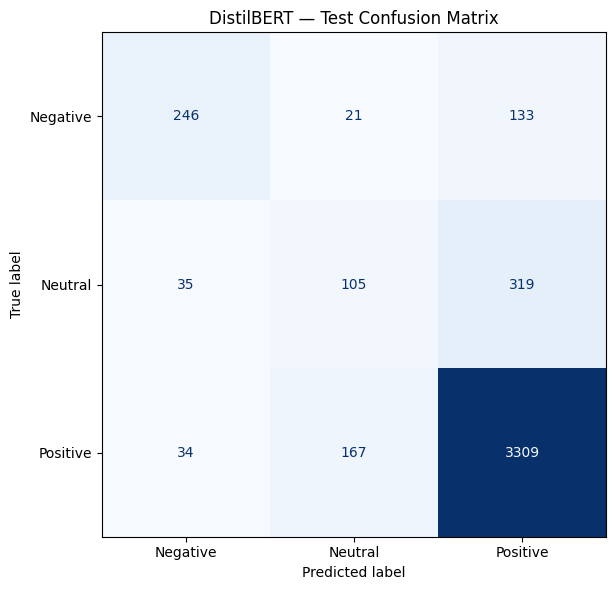


Saved report, predictions, and confusion matrix!


In [36]:

import os
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    f1_score
)

CHECKPOINT = "/kaggle/working/distilbert_best"
TEST_CSV = "/kaggle/working/processed/test.csv"

assert os.path.isdir(CHECKPOINT), "Checkpoint missing!"
assert os.path.isfile(TEST_CSV), "Test CSV missing!"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

tokenizer = AutoTokenizer.from_pretrained(
    CHECKPOINT, local_files_only=True
)

model = AutoModelForSequenceClassification.from_pretrained(
    CHECKPOINT, local_files_only=True
).to(device)

model.eval()

label2id = {"negative": 0, "neutral": 1, "positive": 2}
id2label = {v: k for k, v in label2id.items()}

test_df = pd.read_csv(TEST_CSV).fillna("")

class TestDataset(Dataset):
    def __len__(self):
        return len(test_df)

    def __getitem__(self, idx):
        row = test_df.iloc[idx]
        encoded = tokenizer(
            str(row["text"]),
            str(row["aspect"]),
            truncation=True,
            padding="max_length",
            max_length=128,
            return_tensors="pt"
        )
        item = {k: v.squeeze(0) for k, v in encoded.items()}
        item["labels"] = torch.tensor(
            label2id[row["sentiment"]], dtype=torch.long
        )
        return item

loader = DataLoader(TestDataset(), batch_size=32, shuffle=False)

preds, actual = [], []

with torch.no_grad():
    for batch in tqdm(loader, desc="Evaluating"):
        batch = {k: v.to(device) for k, v in batch.items()}
        logits = model(**batch).logits
        preds.extend(logits.argmax(-1).cpu().tolist())
        actual.extend(batch["labels"].cpu().tolist())

accuracy = accuracy_score(actual, preds)
macro_f1 = f1_score(
    actual, preds, average="macro",
    labels=[0, 1, 2], zero_division=0
)

print("\n===== DISTILBERT TEST RESULTS =====")
print(f"Accuracy: {accuracy:.4f}")
print(f"Macro F1: {macro_f1:.4f}")

report = classification_report(
    actual, preds, labels=[0, 1, 2],
    target_names=["Negative", "Neutral", "Positive"],
    digits=4, zero_division=0
)
print("\n", report)

cm = confusion_matrix(actual, preds, labels=[0, 1, 2])
print("\nConfusion Matrix:\n", cm)

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(
    cm, display_labels=["Negative", "Neutral", "Positive"]
).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)

plt.title("DistilBERT — Test Confusion Matrix")
plt.tight_layout()
plt.savefig(
    "/kaggle/working/distilbert_confusion_matrix.png",
    dpi=300
)
plt.show()

test_df["predicted_sentiment"] = [
    id2label[p] for p in preds
]
test_df.to_csv(
    "/kaggle/working/distilbert_test_predictions.csv",
    index=False
)

with open(
    "/kaggle/working/distilbert_test_report.txt", "w"
) as f:
    f.write(f"Test accuracy: {accuracy:.4f}\n")
    f.write(f"Test macro F1: {macro_f1:.4f}\n\n")
    f.write(report)
    f.write("\nConfusion matrix:\n")
    f.write(str(cm))

print("\nSaved report, predictions, and confusion matrix!")


In [37]:

import pandas as pd
import re
from itertools import combinations

base = "/kaggle/working/processed"

splits = {
    name: pd.read_csv(f"{base}/{name}.csv")
    for name in ["train", "val", "test"]
}

def normalize_text(text):
    return re.sub(
        r"\s+", " ", str(text).lower().strip()
    )

for name, df in splits.items():
    df["normalized_text"] = df["text"].apply(normalize_text)
    print(
        f"{name}: {len(df)} aspects, "
        f"{df['sample_id'].nunique()} unique post IDs"
    )

print("\n===== CROSS-SPLIT LEAKAGE CHECK =====")

for a, b in combinations(splits.keys(), 2):
    df_a, df_b = splits[a], splits[b]

    common_ids = (
        set(df_a["sample_id"])
        & set(df_b["sample_id"])
    )

    common_texts = (
        set(df_a["normalized_text"])
        & set(df_b["normalized_text"])
    )

    print(f"\n{a.upper()} vs {b.upper()}")
    print("Overlapping post IDs:", len(common_ids))
    print("Overlapping exact normalized texts:", len(common_texts))


train: 29885 aspects, 9537 unique post IDs
val: 8603 aspects, 2716 unique post IDs
test: 4369 aspects, 1373 unique post IDs

===== CROSS-SPLIT LEAKAGE CHECK =====

TRAIN vs VAL
Overlapping post IDs: 0
Overlapping exact normalized texts: 48

TRAIN vs TEST
Overlapping post IDs: 0
Overlapping exact normalized texts: 22

VAL vs TEST
Overlapping post IDs: 0
Overlapping exact normalized texts: 13


In [38]:

import pandas as pd

train = splits["train"]
val = splits["val"]
test = splits["test"]

def inspect_overlap(df1, df2, name1, name2):
    shared = (
        set(df1["normalized_text"])
        & set(df2["normalized_text"])
    )

    print(f"\n===== {name1} vs {name2} =====")
    print("Shared distinct texts:", len(shared))

    examples = []

    for text in sorted(shared):
        rows1 = df1[df1["normalized_text"] == text]
        rows2 = df2[df2["normalized_text"] == text]

        examples.append({
            "text": text[:160],
            f"{name1}_ids": ", ".join(
                rows1["sample_id"].astype(str).unique()[:5]
            ),
            f"{name2}_ids": ", ".join(
                rows2["sample_id"].astype(str).unique()[:5]
            ),
            f"{name1}_aspects": ", ".join(
                rows1["aspect"].astype(str).unique()[:5]
            ),
            f"{name2}_aspects": ", ".join(
                rows2["aspect"].astype(str).unique()[:5]
            ),
            f"{name1}_sentiments": ", ".join(
                rows1["sentiment"].astype(str).unique()
            ),
            f"{name2}_sentiments": ", ".join(
                rows2["sentiment"].astype(str).unique()
            )
        })

    result = pd.DataFrame(examples)

    if not result.empty:
        display(result.head(10))

    return result

overlap_train_val = inspect_overlap(
    train, val, "train", "val"
)

overlap_train_test = inspect_overlap(
    train, test, "train", "test"
)

overlap_val_test = inspect_overlap(
    val, test, "val", "test"
)

with pd.ExcelWriter(
    "/kaggle/working/cross_split_overlap_audit.xlsx"
) as writer:
    overlap_train_val.to_excel(
        writer, sheet_name="Train_Val", index=False
    )
    overlap_train_test.to_excel(
        writer, sheet_name="Train_Test", index=False
    )
    overlap_val_test.to_excel(
        writer, sheet_name="Val_Test", index=False
    )

print("\nOverlap audit saved successfully!")



===== train vs val =====
Shared distinct texts: 48


,text,train_ids,val_ids,train_aspects,val_aspects,train_sentiments,val_sentiments
0,#affirmation of the day #chiropractic #vancouver,"17079, 17236, 17251, 17492, 17579",17636,"Stoicism, Buddhism, Vancouver, Affirmations, R...","Affirmations, Think and grow rich, The power o...","positive, neutral","positive, neutral"
1,#indoorsoccer tonight 930-1130p @metrogolfdome...,16608,16565,"Toronto fc, York9 fc, Metro golf dome, Monday ...","Toronto fc, York9 fc, Spanish-speaking communi...",positive,positive
2,#selfiefornash @nashgrier ???? not the best pi...,"20790, 21009, 21036",20785,"Nash grier, #selfiefornash campaign, Dipg, #se...","Nash grier, #selfiefornash"" campaign, Dipg","positive, negative","positive, negative"
3,#selfiefornash @nashgrier don't mind the way i...,20877,20863,"Nash grier, #selfiefornash","Nash grier, #selfiefornash",positive,positive
4,#selfiefornash @nashgrier i'm nicole and i lov...,"20747, 20748, 20754, 20768, 20821","20983, 21004","Nash grier, Waffles, Public shaming, Nicole","Waffles, Nash grier","positive, negative",positive
5,#selfiefornash @nashgrier you've helped me get...,"20781, 21029",20929,"Nashgrier, Nash, Mental health awareness",Nashgrier,positive,positive
6,#selfiefornash @nashgrier you've helped me get...,"20779, 20799, 20852",20915,"Nashgrier, Nash, Instagram, Twitter",Nash,positive,positive
7,#selfiefornash @nashgrier you've helped me get...,20924,20985,"Instagram, Twitter, Facebook, Nashgrier",Nashgrier,"neutral, positive",positive
8,#sheskindahotvma rt to vote,"8582, 9434, 9526, 9548","9387, 9480, 9634","Rosarrows, Coachella, Lollapalooza, Alternativ...","Audience participation via retweets, #sheskind...",positive,"positive, neutral"
9,#swordartonlineii begins in 3....2.....1.....#...,13486,14894,"Sword art online, Reki kawahara, Silica, Toonami","Sword art online, Reki kawahara, Kirito, Asuna...","positive, neutral",positive



===== train vs test =====
Shared distinct texts: 22


,text,train_ids,test_ids,train_aspects,test_aspects,train_sentiments,test_sentiments
0,#selfiefornash @nashgrier don't mind the way i...,20877,20954,"Nash grier, #selfiefornash",Nash grier,positive,negative
1,#selfiefornash @nashgrier you've helped me get...,"20779, 20799, 20852",21025,"Nashgrier, Nash, Instagram, Twitter",Nashgrier,positive,positive
2,#sheskindahotvma rt to vote,"8582, 9434, 9526, 9548",9519,"Rosarrows, Coachella, Lollapalooza, Alternativ...","Tyler joseph, Twenty one pilots, Drake, Online...",positive,"positive, negative"
3,#vancouver oct 1/2: manage corp exposure to cl...,17210,17356,"Climate change, Kyoto protocol, Paris agreement","University of toronto, Simon fraser university...","negative, positive",positive
4,@pjraven convention oth #montreal ??????,18396,18147,Photography,Montreal,positive,positive
5,@robertplant &amp; the sensational space shift...,15617,16273,"Alex grey, Peter max, The beatles, Jimi hendri...","Alex grey, Peter max, The beatles, Jimi hendri...",positive,positive
6,"canada, at this time in history @pmharper #elx...",2738,2588,"Stephen harper, Canada, Justin trudeau","Justin trudeau, Liberal party","positive, neutral",positive
7,"good morning, st. john's, nl. #canada http://t...","10230, 10311, 10350, 10510, 10578","10463, 10622","St. john's, Offshore oil and gas, Major fire, ...","Great fire of 1892, St. john's newfoundland an...","negative, neutral, positive","neutral, negative, positive"
8,happy #nationaldogday,"7676, 7734, 7810, 7844, 7982",8456,"National dog day, Dogs, Welfare, Shelters and ...","Rescue dogs, Dogs, National dog day","positive, negative, neutral",positive
9,happy #nationaldogday celebrating with photo o...,7770,7654,"Farm dog, Working animals, Border collies, Aus...","Atv (all-terrain vehicle), Border collies and ...",positive,neutral



===== val vs test =====
Shared distinct texts: 13


,text,val_ids,test_ids,val_aspects,test_aspects,val_sentiments,test_sentiments
0,#selfiefornash @nashgrier don't mind the way i...,20863,20954,"Nash grier, #selfiefornash",Nash grier,positive,negative
1,#selfiefornash @nashgrier you've helped me get...,20915,21025,Nash,Nashgrier,positive,positive
2,#sheskindahotvma rt to vote,"9387, 9480, 9634",9519,"Audience participation via retweets, #sheskind...","Tyler joseph, Twenty one pilots, Drake, Online...","positive, neutral","positive, negative"
3,***??????????***for a limited time***?????????...,15012,13666,Tommy crown's treasure chest,Tommy crown,positive,positive
4,@robertplant &amp; the sensational space shift...,16069,16273,"Alex grey, Peter max, The beatles, Jimi hendri...","Alex grey, Peter max, The beatles, Jimi hendri...",positive,positive
5,"good morning, st. john's, nl. #canada http://t...","10201, 10259, 10386, 10762, 10921","10463, 10622","Newfoundland and labrador, Great fire of 1892,...","Great fire of 1892, St. john's newfoundland an...","neutral, negative","neutral, negative, positive"
6,happy #nationaldogday,"8222, 8415, 8494",8456,"Golden retriever, National dog day, Colleen pa...","Rescue dogs, Dogs, National dog day",positive,positive
7,happy #nationaldogday ????,8441,8085,"Shiba inu, National dog day, Colleen paige","National dog day, Colleen paige, Dogs",positive,positive
8,let's go #bluejays #tdtuesday,5351,5819,"Toronto blue jays, Rogers centre, Td bank","Toronto blue jays, Joe carter, Roberto alomar,...",positive,positive
9,let's go blue jays! #tdtuesday #bluejays,"5339, 5365, 5859, 5933","5491, 5597, 5959","Toronto blue jays, Joe carter, Vladimir guerre...","Joe carter, Roberto alomar, Toronto blue jays","positive, neutral",positive



Overlap audit saved successfully!


In [39]:

import pandas as pd
import re
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

base = "/kaggle/working"

train = pd.read_csv(f"{base}/processed/train.csv")
test = pd.read_csv(
    f"{base}/distilbert_test_predictions.csv"
)

def normalize(text):
    return re.sub(
        r"\s+", " ", str(text).lower().strip()
    )

train_texts = set(
    train["text"].fillna("").apply(normalize)
)

test["normalized_text"] = (
    test["text"].fillna("").apply(normalize)
)

clean_test = test[
    ~test["normalized_text"].isin(train_texts)
].copy()

print("Original test aspects:", len(test))
print("Overlapping test aspects removed:",
      len(test) - len(clean_test))
print("Remaining test aspects:", len(clean_test))

print("\n===== NON-OVERLAPPING TEST RESULTS =====")

print("Accuracy:", round(
    accuracy_score(
        clean_test["sentiment"],
        clean_test["predicted_sentiment"]
    ), 4
))

print("Macro F1:", round(
    f1_score(
        clean_test["sentiment"],
        clean_test["predicted_sentiment"],
        labels=["negative", "neutral", "positive"],
        average="macro",
        zero_division=0
    ), 4
))

print("\nClassification Report:")
print(classification_report(
    clean_test["sentiment"],
    clean_test["predicted_sentiment"],
    labels=["negative", "neutral", "positive"],
    digits=4,
    zero_division=0
))

clean_test.drop(
    columns=["normalized_text"]
).to_csv(
    f"{base}/distilbert_nonoverlap_test_predictions.csv",
    index=False
)

print("\nNon-overlapping predictions saved!")


Original test aspects: 4369
Overlapping test aspects removed: 140
Remaining test aspects: 4229

===== NON-OVERLAPPING TEST RESULTS =====
Accuracy: 0.8354
Macro F1: 0.6257

Classification Report:
              precision    recall  f1-score   support

    negative     0.7827    0.6187    0.6911       396
     neutral     0.3592    0.2262    0.2776       451
    positive     0.8772    0.9420    0.9085      3382

    accuracy                         0.8354      4229
   macro avg     0.6730    0.5956    0.6257      4229
weighted avg     0.8131    0.8354    0.8208      4229


Non-overlapping predictions saved!


In [41]:

import numpy as np
import pandas as pd
import torch

from tqdm.auto import tqdm
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

classes = ["negative", "neutral", "positive"]
label2id = {c: i for i, c in enumerate(classes)}

# Use the test dataframe already loaded
test = test.reset_index(drop=True)

class TestDataset(Dataset):
    def __len__(self):
        return len(test)

    def __getitem__(self, idx):
        row = test.iloc[idx]

        encoded = tokenizer(
            str(row["text"]),
            str(row["aspect"]),
            truncation=True,
            padding="max_length",
            max_length=128,
            return_tensors="pt"
        )

        return {
            k: v.squeeze(0)
            for k, v in encoded.items()
        }

loader = DataLoader(
    TestDataset(),
    batch_size=32,
    shuffle=False
)

model.eval()
model.to(device)

all_probs = []

with torch.no_grad():
    for batch in tqdm(loader, desc="Evaluating DistilBERT"):
        batch = {
            k: v.to(device)
            for k, v in batch.items()
        }

        logits = model(**batch).logits

        batch_probs = torch.softmax(
            logits, dim=-1
        )

        all_probs.append(
            batch_probs.cpu().numpy()
        )

probs = np.concatenate(all_probs, axis=0)

y_true = test["sentiment"].map(label2id).to_numpy()
y_pred = probs.argmax(axis=1)

print("Predictions generated successfully!")
print("Test examples:", len(test))
print("Accuracy:", accuracy_score(y_true, y_pred))
print("Macro F1:", f1_score(y_true, y_pred, average="macro"))


Evaluating DistilBERT:   0%|          | 0/137 [00:00<?, ?it/s]

Predictions generated successfully!
Test examples: 4369
Accuracy: 0.8377203021286336
Macro F1: 0.6258527925545984


In [42]:

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("========== MODEL DIAGNOSTICS ==========")

print("Test examples:", len(test))
print("Model device:", device)

print("\nModel label mapping:")
print(model.config.id2label)

print("\nActual label distribution:")
print(test["sentiment"].value_counts())

print("\nPredicted label distribution:")
print(pd.Series(
    [classes[i] for i in y_pred]
).value_counts())

print("\nAccuracy:", accuracy_score(y_true, y_pred))
print("Macro F1:", f1_score(
    y_true, y_pred, average="macro"
))

print("\nClassification Report:")
print(classification_report(
    y_true,
    y_pred,
    labels=[0, 1, 2],
    target_names=classes,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_true, y_pred, labels=[0, 1, 2]
))

print("\nFirst 10 predictions:")
display(pd.DataFrame({
    "Actual": test["sentiment"].head(10).values,
    "Predicted": [classes[i] for i in y_pred[:10]],
    "Confidence": probs.max(axis=1)[:10]
}))


========== MODEL DIAGNOSTICS ==========
Test examples: 4369
Model device: cuda

Model label mapping:
{0: 'negative', 1: 'neutral', 2: 'positive'}

Actual label distribution:
sentiment
positive    3510
neutral      459
negative     400
Name: count, dtype: int64

Predicted label distribution:
positive    3761
negative     315
neutral      293
Name: count, dtype: int64

Accuracy: 0.8377203021286336
Macro F1: 0.6258527925545984

Classification Report:
              precision    recall  f1-score   support

    negative       0.78      0.61      0.69       400
     neutral       0.36      0.23      0.28       459
    positive       0.88      0.94      0.91      3510

    accuracy                           0.84      4369
   macro avg       0.67      0.60      0.63      4369
weighted avg       0.82      0.84      0.82      4369


Confusion Matrix:
[[ 246   21  133]
 [  35  105  319]
 [  34  167 3309]]

First 10 predictions:


,Actual,Predicted,Confidence
0,positive,positive,0.956419
1,positive,positive,0.982679
2,positive,positive,0.988929
3,neutral,positive,0.848852
4,positive,positive,0.900214
5,negative,negative,0.942417
6,positive,positive,0.961955
7,negative,negative,0.980913
8,negative,negative,0.583014
9,positive,positive,0.982811


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Computing probabilities:   0%|          | 0/133 [00:00<?, ?it/s]

Evaluation completed successfully
Accuracy: 0.8354
Macro F1: 0.6257


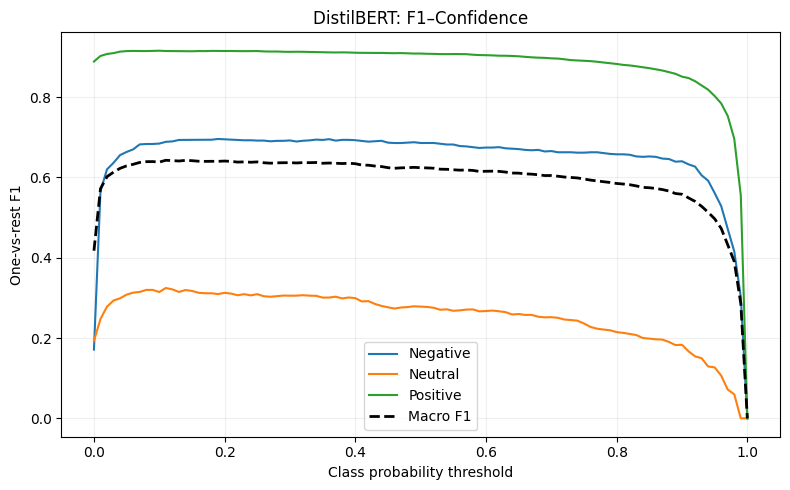

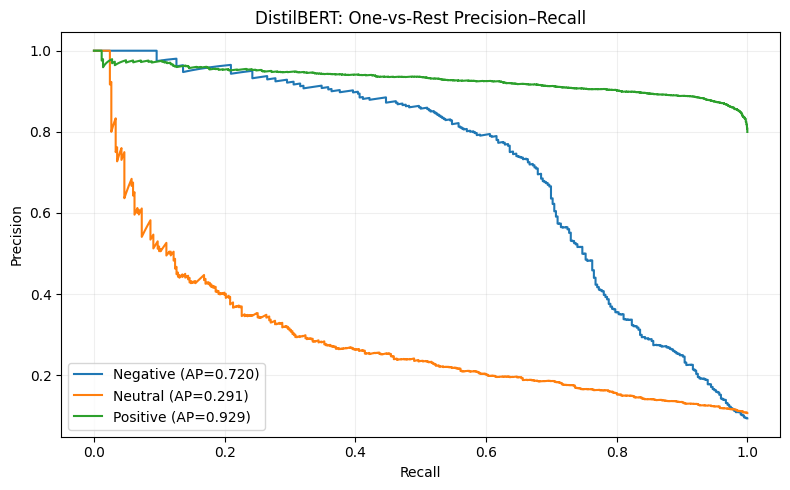

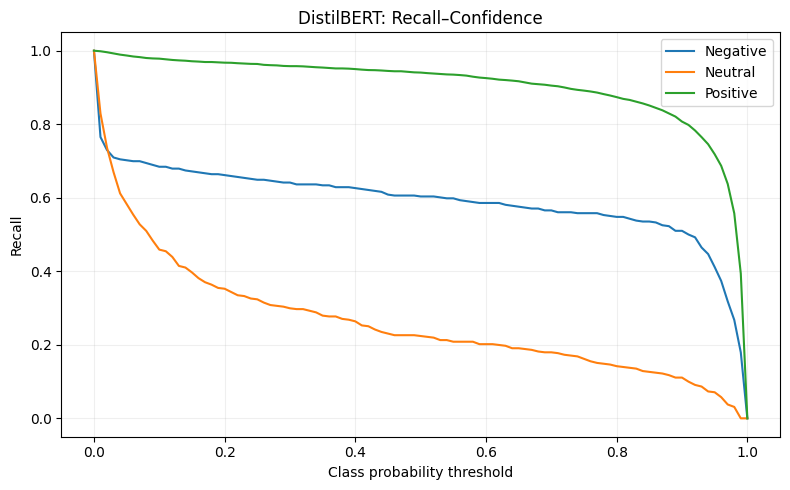

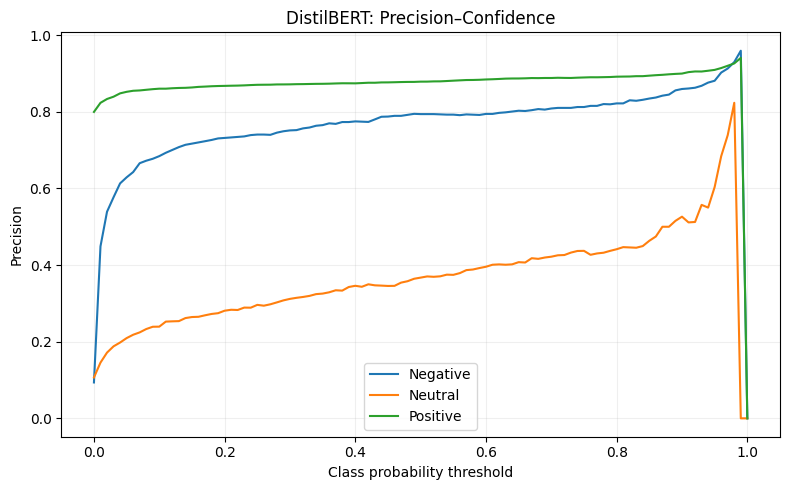

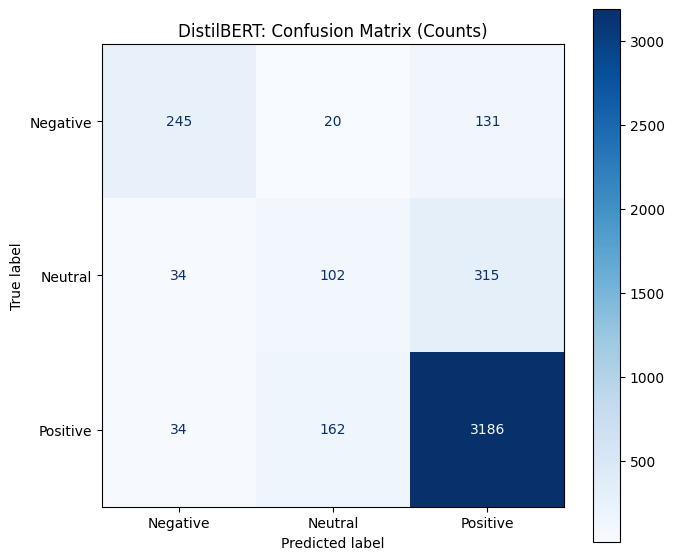

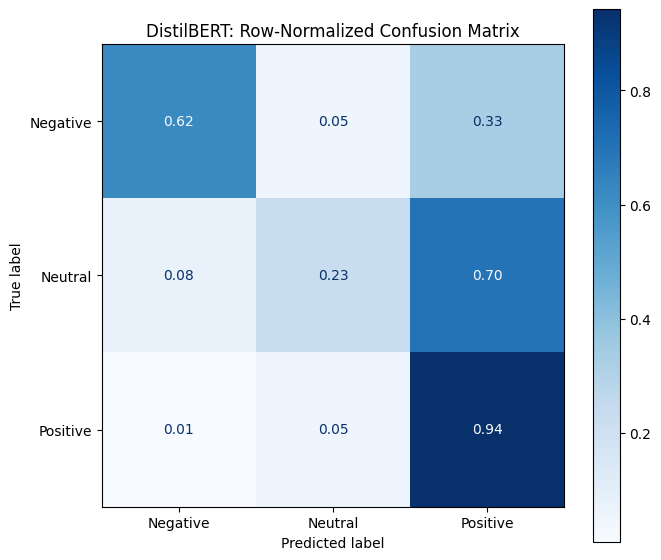


All six evaluation figures saved to: /kaggle/working/research_figures
Evaluated examples: 4229
Macro F1: 0.6257


In [43]:

import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt

from tqdm.auto import tqdm
from sklearn.metrics import accuracy_score, f1_score
from torch.utils.data import Dataset, DataLoader
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification
)
from sklearn.metrics import (
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    average_precision_score
)

OUT = "/kaggle/working/research_figures"
os.makedirs(OUT, exist_ok=True)

CKPT = "/kaggle/working/distilbert_best"
BASE = "/kaggle/working/processed"

classes = ["negative", "neutral", "positive"]
label2id = {c: i for i, c in enumerate(classes)}

train = pd.read_csv(f"{BASE}/train.csv").fillna("")
test = pd.read_csv(f"{BASE}/test.csv").fillna("")

# Reproduce the exact-text non-overlap check
def norm(s):
    return " ".join(str(s).lower().split())

train_texts = set(train["text"].map(norm))
test = test[
    ~test["text"].map(norm).isin(train_texts)
].copy().reset_index(drop=True)

device = "cuda" if torch.cuda.is_available() else "cpu"

tokenizer = AutoTokenizer.from_pretrained(
    CKPT, local_files_only=True
)
model = AutoModelForSequenceClassification.from_pretrained(
    CKPT, local_files_only=True
).to(device).eval()

class EvaluationDataset(Dataset):
    def __len__(self):
        return len(test)

    def __getitem__(self, idx):
        row = test.iloc[idx]
        encoded = tokenizer(
            str(row["text"]),
            str(row["aspect"]),
            truncation=True,
            padding="max_length",
            max_length=128,
            return_tensors="pt"
        )
        return {
            k: v.squeeze(0)
            for k, v in encoded.items()
        }

loader = DataLoader(
    EvaluationDataset(), batch_size=32, shuffle=False
)

probabilities = []

with torch.no_grad():
    for batch in tqdm(loader, desc="Computing probabilities"):
        batch = {k: v.to(device) for k, v in batch.items()}
        logits = model(**batch).logits
        probabilities.append(
            torch.softmax(logits, dim=-1).cpu().numpy()
        )

probs = np.concatenate(probabilities)
y_true = test["sentiment"].map(label2id).to_numpy()
y_pred = probs.argmax(axis=1)

# Verify checkpoint reproduces known evaluation
assert len(test) == 4229

accuracy = accuracy_score(y_true, y_pred)
macro_f1 = f1_score(y_true, y_pred, average="macro")

assert len(test) == 4229, "Unexpected test size"
assert np.isfinite(probs).all(), "Invalid probabilities"
assert np.allclose(probs.sum(axis=1), 1, atol=1e-5), "Invalid softmax probabilities"

print("Evaluation completed successfully")
print(f"Accuracy: {accuracy:.4f}")
print(f"Macro F1: {macro_f1:.4f}")

if abs(macro_f1 - 0.6243) > 0.002:
    print("WARNING: Results differ from the previous evaluation.")
    print("Verify checkpoint and preprocessing before finalizing paper metrics.")

# Save probabilities for reproducibility
for i, c in enumerate(classes):
    test[f"prob_{c}"] = probs[:, i]
test["predicted_sentiment"] = [
    classes[i] for i in y_pred
]
test.to_csv(f"{OUT}/predictions_with_probabilities.csv",
            index=False)

thresholds = np.linspace(0, 1, 101)
precision_values = {}
recall_values = {}
f1_values = {}

for i, c in enumerate(classes):
    binary_true = (y_true == i).astype(int)

    precision_values[c] = []
    recall_values[c] = []
    f1_values[c] = []

    for t in thresholds:
        binary_pred = (probs[:, i] >= t).astype(int)

        precision_values[c].append(
            precision_score(binary_true, binary_pred,
                            zero_division=0)
        )
        recall_values[c].append(
            recall_score(binary_true, binary_pred,
                         zero_division=0)
        )
        f1_values[c].append(
            f1_score(binary_true, binary_pred,
                     zero_division=0)
        )

def save_plot(name):
    plt.tight_layout()
    plt.savefig(
        f"{OUT}/{name}.png",
        dpi=300, bbox_inches="tight"
    )
    plt.show()
    plt.close()

# 1. F1-confidence
plt.figure(figsize=(8, 5))
for c in classes:
    plt.plot(thresholds, f1_values[c], label=c.title())

macro_curve = np.mean(
    [f1_values[c] for c in classes], axis=0
)
plt.plot(thresholds, macro_curve, "k--",
         linewidth=2, label="Macro F1")
plt.xlabel("Class probability threshold")
plt.ylabel("One-vs-rest F1")
plt.title("DistilBERT: F1–Confidence")
plt.legend()
plt.grid(alpha=0.2)
save_plot("01_f1_confidence")

# 2. Precision-recall
plt.figure(figsize=(8, 5))
for i, c in enumerate(classes):
    truth = (y_true == i).astype(int)
    p, r, _ = precision_recall_curve(truth, probs[:, i])
    ap = average_precision_score(truth, probs[:, i])
    plt.plot(r, p, label=f"{c.title()} (AP={ap:.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("DistilBERT: One-vs-Rest Precision–Recall")
plt.legend()
plt.grid(alpha=0.2)
save_plot("02_precision_recall")

# 3. Recall-confidence
plt.figure(figsize=(8, 5))
for c in classes:
    plt.plot(thresholds, recall_values[c], label=c.title())
plt.xlabel("Class probability threshold")
plt.ylabel("Recall")
plt.title("DistilBERT: Recall–Confidence")
plt.legend()
plt.grid(alpha=0.2)
save_plot("03_recall_confidence")

# 4. Precision-confidence
plt.figure(figsize=(8, 5))
for c in classes:
    plt.plot(thresholds, precision_values[c], label=c.title())
plt.xlabel("Class probability threshold")
plt.ylabel("Precision")
plt.title("DistilBERT: Precision–Confidence")
plt.legend()
plt.grid(alpha=0.2)
save_plot("04_precision_confidence")

# 5. Original confusion matrix (counts)
cm = confusion_matrix(y_true, y_pred, labels=[0, 1, 2])

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(
    cm, display_labels=[c.title() for c in classes]
).plot(ax=ax, cmap="Blues", values_format="d")
ax.set_title("DistilBERT: Confusion Matrix (Counts)")
save_plot("05_confusion_matrix_counts")

# 6. Normalized confusion matrix
cm_norm = confusion_matrix(
    y_true, y_pred, labels=[0, 1, 2],
    normalize="true"
)

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(
    cm_norm, display_labels=[c.title() for c in classes]
).plot(ax=ax, cmap="Blues", values_format=".2f")
ax.set_title("DistilBERT: Row-Normalized Confusion Matrix")
save_plot("06_confusion_matrix_normalized")

print("\nAll six evaluation figures saved to:", OUT)
print("Evaluated examples:", len(test))
print("Macro F1:", round(
    f1_score(y_true, y_pred, average="macro"), 4
))


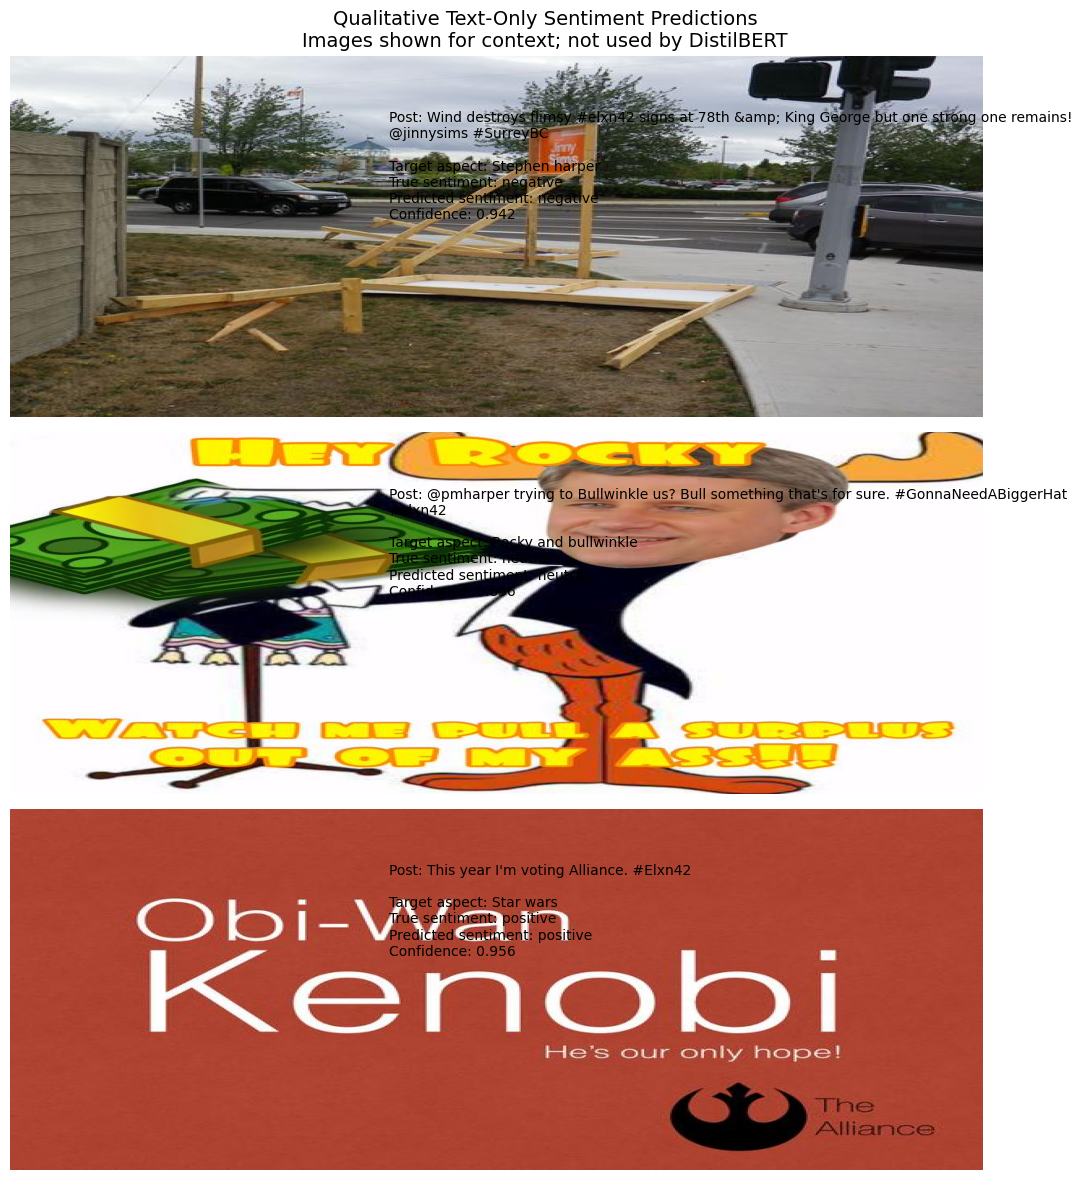

In [44]:

from PIL import Image
import matplotlib.pyplot as plt
import os

examples = []

for sentiment in classes:
    subset = test[
        (test["sentiment"] == sentiment) &
        (test["predicted_sentiment"] == sentiment)
    ]
    if len(subset):
        examples.append(subset.iloc[0])

fig, axes = plt.subplots(
    len(examples), 1,
    figsize=(11, 4 * len(examples)),
    squeeze=False
)

for ax_row, row in zip(axes, examples):
    ax = ax_row[0]
    ax.axis("off")

    image_path = row["image_path"]
    if os.path.isfile(image_path):
        img = Image.open(image_path).convert("RGB")
        ax.imshow(img, extent=[0, 0.34, 0.15, 0.95],
                  aspect="auto")

    predicted = row["predicted_sentiment"]
    confidence = row[f"prob_{predicted}"]

    description = (
        f"Post: {str(row['text'])[:220]}\n\n"
        f"Target aspect: {row['aspect']}\n"
        f"True sentiment: {row['sentiment']}\n"
        f"Predicted sentiment: {predicted}\n"
        f"Confidence: {confidence:.3f}"
    )

    ax.text(
        0.39, 0.85, description,
        transform=ax.transAxes,
        va="top", fontsize=10,
        wrap=True
    )

fig.suptitle(
    "Qualitative Text-Only Sentiment Predictions\n"
    "Images shown for context; not used by DistilBERT",
    fontsize=14
)

plt.tight_layout()
plt.savefig(
    f"{OUT}/07_qualitative_examples.png",
    dpi=300, bbox_inches="tight"
)
plt.show()


In [46]:

import os
import zipfile
import pandas as pd
from pathlib import Path

# Load predictions with confidence scores
csv_path = (
    "/kaggle/working/research_figures/"
    "predictions_with_probabilities.csv"
)

df = pd.read_csv(csv_path).fillna("")

# Select examples for qualitative analysis
df["correct"] = (
    df["sentiment"] == df["predicted_sentiment"]
)

# Target: 20 images across correct and incorrect cases
quotas = {
    ("positive", True): 4,
    ("positive", False): 3,
    ("negative", True): 4,
    ("negative", False): 3,
    ("neutral", True): 3,
    ("neutral", False): 3
}

selected_parts = []
used_ids = set()

for (sentiment, correct), count in quotas.items():
    subset = df[
        (df["sentiment"] == sentiment) &
        (df["correct"] == correct)
    ].copy()

    subset["confidence"] = subset.apply(
        lambda row: row[
            f"prob_{row['predicted_sentiment']}"
        ],
        axis=1
    )

    # Prefer reasonably confident examples
    subset = subset.sort_values(
        "confidence", ascending=False
    )

    subset = subset[
        ~subset["sample_id"].astype(str).isin(used_ids)
    ]

    chosen = subset.head(count)
    selected_parts.append(chosen)

    used_ids.update(
        chosen["sample_id"].astype(str)
    )

selected = pd.concat(
    selected_parts, ignore_index=True
)

# Package images and prediction metadata
zip_path = "/kaggle/working/ImplicitMABSA_20_Examples.zip"

with zipfile.ZipFile(
    zip_path, "w", zipfile.ZIP_DEFLATED
) as z:
    metadata_path = (
        "/kaggle/working/"
        "qualitative_examples_metadata.csv"
    )

    selected.to_csv(metadata_path, index=False)
    z.write(metadata_path, arcname="metadata.csv")

    found = 0

    for _, row in selected.iterrows():
        image_path = Path(str(row["image_path"]))

        if image_path.exists():
            z.write(
                image_path,
                arcname=f"images/{image_path.name}"
            )
            found += 1
        else:
            print("Missing:", image_path)

print("Selected examples:", len(selected))
print("Images included:", found)
print("ZIP saved:", zip_path)

print("\nSelection breakdown:")
print(
    selected.groupby(
        ["sentiment", "correct"]
    ).size()
)


Selected examples: 20
Images included: 20
ZIP saved: /kaggle/working/ImplicitMABSA_20_Examples.zip

Selection breakdown:
sentiment  correct
negative   False      3
           True       4
neutral    False      3
           True       3
positive   False      3
           True       4
dtype: int64


/usr/lib/python3.13/zipfile/__init__.py:1686: UserWarning: Duplicate name: 'images/8063.jpg'
  return self._open_to_write(zinfo, force_zip64=force_zip64)


In [47]:

# ============================================================
# MODEL 2 — MOBILENETV3-SMALL
# IMAGE-ONLY SENTIMENT CLASSIFICATION
# ============================================================

import os
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from PIL import Image
from tqdm.auto import tqdm

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import (
    mobilenet_v3_small,
    MobileNet_V3_Small_Weights
)

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    precision_recall_curve,
    average_precision_score
)

SEED = 42
BATCH_SIZE = 32
EPOCHS = 15
PATIENCE = 4
LR = 1e-4
WEIGHT_DECAY = 1e-4

classes_img = ["negative", "neutral", "positive"]
label2id_img = {
    label: i for i, label in enumerate(classes_img)
}

device_img = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

BASE_IMG = Path("/kaggle/working/processed")
OUT_IMG = Path("/kaggle/working/mobilenetv3_results")
FIG_IMG = OUT_IMG / "figures"

OUT_IMG.mkdir(parents=True, exist_ok=True)
FIG_IMG.mkdir(parents=True, exist_ok=True)

train_img = pd.read_csv(BASE_IMG / "train.csv").fillna("")
val_img = pd.read_csv(BASE_IMG / "val.csv").fillna("")
test_img = pd.read_csv(BASE_IMG / "test.csv").fillna("")

print("Device:", device_img)
print("Training examples:", len(train_img))
print("Validation examples:", len(val_img))
print("Testing examples:", len(test_img))

print("\nTraining class distribution:")
print(train_img["sentiment"].value_counts())


Device: cuda
Training examples: 29885
Validation examples: 8603
Testing examples: 4369

Training class distribution:
sentiment
positive    24065
neutral      3289
negative     2531
Name: count, dtype: int64


In [48]:

DATASET_ROOT_IMG = Path(
    "/kaggle/input/datasets/"
    "manaswitashrivastav/implicitmabsa-ox-mabsr"
)

def resolve_image(row):
    original = Path(str(row["image_path"]))

    if original.is_file():
        return str(original)

    sample_id = str(row["sample_id"]).strip()

    candidates = [
        DATASET_ROOT_IMG / "img_text" / f"{sample_id}.jpg",
        DATASET_ROOT_IMG / "data" / "img_text" / f"{sample_id}.jpg",
        DATASET_ROOT_IMG / original.name
    ]

    for path in candidates:
        if path.is_file():
            return str(path)

    return ""

for df in [train_img, val_img, test_img]:
    df["resolved_image_path"] = df.apply(
        resolve_image, axis=1
    )

for name, df in [
    ("Train", train_img),
    ("Validation", val_img),
    ("Test", test_img)
]:
    missing = (df["resolved_image_path"] == "").sum()
    print(f"{name}: {missing} missing images")

    if missing:
        print(
            df.loc[
                df["resolved_image_path"] == "",
                ["sample_id", "image_path"]
            ].head()
        )

assert all(
    (df["resolved_image_path"] != "").all()
    for df in [train_img, val_img, test_img]
), "Some images are missing. Check dataset paths."

print("\nAll image paths verified successfully!")


Train: 0 missing images
Validation: 0 missing images
Test: 0 missing images

All image paths verified successfully!


In [49]:

train_transform_img = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(
        224, scale=(0.8, 1.0)
    ),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform_img = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class ImageDataset(Dataset):
    def __init__(self, df, transform):
        self.df = df.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        with Image.open(
            row["resolved_image_path"]
        ) as img:
            image = self.transform(
                img.convert("RGB")
            )

        label = label2id_img[row["sentiment"]]

        return image, torch.tensor(
            label, dtype=torch.long
        )

train_loader_img = DataLoader(
    ImageDataset(train_img, train_transform_img),
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

val_loader_img = DataLoader(
    ImageDataset(val_img, eval_transform_img),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

test_loader_img = DataLoader(
    ImageDataset(test_img, eval_transform_img),
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=torch.cuda.is_available()
)

images, labels = next(iter(train_loader_img))

print("Image batch shape:", images.shape)
print("Labels shape:", labels.shape)


Image batch shape: torch.Size([32, 3, 224, 224])
Labels shape: torch.Size([32])


In [50]:

weights_img = MobileNet_V3_Small_Weights.DEFAULT

mobilenet_model = mobilenet_v3_small(
    weights=weights_img
)

# Replace the original 1000-class ImageNet output
in_features = mobilenet_model.classifier[-1].in_features

mobilenet_model.classifier[-1] = nn.Linear(
    in_features, 3
)

mobilenet_model = mobilenet_model.to(device_img)

print("Model: MobileNetV3-Small")
print(
    "Total parameters:",
    sum(p.numel() for p in mobilenet_model.parameters())
)
print(
    "Trainable parameters:",
    sum(
        p.numel()
        for p in mobilenet_model.parameters()
        if p.requires_grad
    )
)


Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 177MB/s]

Model: MobileNetV3-Small
Total parameters: 1520931
Trainable parameters: 1520931


In [51]:

class_counts_img = (
    train_img["sentiment"]
    .value_counts()
    .reindex(classes_img)
    .to_numpy()
)

weights_class_img = (
    len(train_img) /
    (len(classes_img) * class_counts_img)
)

weights_class_img = torch.tensor(
    weights_class_img,
    dtype=torch.float32,
    device=device_img
)

criterion_img = nn.CrossEntropyLoss(
    weight=weights_class_img
)

optimizer_img = torch.optim.AdamW(
    mobilenet_model.parameters(),
    lr=LR,
    weight_decay=WEIGHT_DECAY
)

scheduler_img = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer_img,
    T_max=EPOCHS
)

print("Class weights:", weights_class_img)
print("Optimizer: AdamW")
print("Learning rate:", LR)


Class weights: tensor([3.9359, 3.0288, 0.4139], device='cuda:0')
Optimizer: AdamW
Learning rate: 0.0001


In [54]:

def evaluate_epoch_img(loader, training=False):

    if training:
        mobilenet_model.train()
    else:
        mobilenet_model.eval()

    total_loss = 0
    y_true_epoch = []
    y_pred_epoch = []
    all_probs_epoch = []

    for images, labels in tqdm(
        loader,
        desc="Training" if training else "Evaluating",
        leave=False
    ):
        images = images.to(device_img)
        labels = labels.to(device_img)

        if training:
            optimizer_img.zero_grad(set_to_none=True)

        with torch.set_grad_enabled(training):
            logits = mobilenet_model(images)
            loss = criterion_img(logits, labels)

            if training:
                loss.backward()
                optimizer_img.step()

        probs_batch = torch.softmax(
            logits.detach(), dim=1
        )

        preds = probs_batch.argmax(dim=1)

        total_loss += loss.item() * images.size(0)

        y_true_epoch.extend(
            labels.cpu().numpy()
        )
        y_pred_epoch.extend(
            preds.cpu().numpy()
        )
        all_probs_epoch.append(
            probs_batch.cpu().numpy()
        )

    y_true_epoch = np.array(y_true_epoch)
    y_pred_epoch = np.array(y_pred_epoch)
    all_probs_epoch = np.concatenate(all_probs_epoch)

    return {
        "loss": total_loss / len(loader.dataset),
        "accuracy": accuracy_score(
            y_true_epoch, y_pred_epoch
        ),
        "macro_f1": f1_score(
            y_true_epoch,
            y_pred_epoch,
            average="macro",
            labels=[0, 1, 2],
            zero_division=0
        ),
        "y_true": y_true_epoch,
        "y_pred": y_pred_epoch,
        "probs": all_probs_epoch
    }


In [55]:

history_img = []

best_f1_img = -1
best_epoch_img = 0
no_improvement_img = 0

checkpoint_img = (
    OUT_IMG / "mobilenetv3_small_best.pth"
)

for epoch in range(1, EPOCHS + 1):

    print(f"\nEpoch {epoch}/{EPOCHS}")

    train_metrics_img = evaluate_epoch_img(
        train_loader_img, training=True
    )

    val_metrics_img = evaluate_epoch_img(
        val_loader_img, training=False
    )

    scheduler_img.step()

    history_img.append({
        "epoch": epoch,
        "train_loss": train_metrics_img["loss"],
        "train_macro_f1": train_metrics_img["macro_f1"],
        "val_loss": val_metrics_img["loss"],
        "val_macro_f1": val_metrics_img["macro_f1"],
        "val_accuracy": val_metrics_img["accuracy"]
    })

    print(
        f"Train loss: {train_metrics_img['loss']:.4f} | "
        f"Train F1: {train_metrics_img['macro_f1']:.4f}"
    )

    print(
        f"Val loss: {val_metrics_img['loss']:.4f} | "
        f"Val F1: {val_metrics_img['macro_f1']:.4f} | "
        f"Val accuracy: {val_metrics_img['accuracy']:.4f}"
    )

    if val_metrics_img["macro_f1"] > best_f1_img:

        best_f1_img = val_metrics_img["macro_f1"]
        best_epoch_img = epoch
        no_improvement_img = 0

        torch.save({
            "model_state_dict": mobilenet_model.state_dict(),
            "epoch": epoch,
            "val_macro_f1": best_f1_img,
            "classes": classes_img
        }, checkpoint_img)

        print("Best checkpoint saved!")

    else:
        no_improvement_img += 1

    if no_improvement_img >= PATIENCE:
        print("Early stopping triggered.")
        break

history_df_img = pd.DataFrame(history_img)

history_df_img.to_csv(
    OUT_IMG / "training_history.csv",
    index=False
)

print("\nTraining completed!")
print("Best epoch:", best_epoch_img)
print("Best validation Macro F1:", best_f1_img)
print("Checkpoint:", checkpoint_img)



Epoch 1/15


Training:   0%|          | 0/934 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/269 [00:00<?, ?it/s]

Train loss: 1.0338 | Train F1: 0.3725
Val loss: 1.0401 | Val F1: 0.3757 | Val accuracy: 0.4985
Best checkpoint saved!

Epoch 2/15


Training:   0%|          | 0/934 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/269 [00:00<?, ?it/s]

... (15 outputs left out)

Train loss: 0.6227 | Train F1: 0.5901
Val loss: 1.2395 | Val F1: 0.3908 | Val accuracy: 0.5546

Epoch 8/15


Training:   0%|          | 0/934 [00:00<?, ?it/s]

Evaluating:   0%|          | 0/269 [00:00<?, ?it/s]

Train loss: 0.5967 | Train F1: 0.6064
Val loss: 1.2698 | Val F1: 0.3942 | Val accuracy: 0.5607
Early stopping triggered.

Training completed!
Best epoch: 4
Best validation Macro F1: 0.3992372000251084
Checkpoint: /kaggle/working/mobilenetv3_results/mobilenetv3_small_best.pth


In [56]:

checkpoint_data_img = torch.load(
    checkpoint_img,
    map_location=device_img,
    weights_only=True
)

mobilenet_model.load_state_dict(
    checkpoint_data_img["model_state_dict"]
)

mobilenet_model.eval()

test_metrics_img = evaluate_epoch_img(
    test_loader_img, training=False
)

y_true_img = test_metrics_img["y_true"]
y_pred_img = test_metrics_img["y_pred"]
probs_img = test_metrics_img["probs"]

print("\n========== MOBILENETV3 TEST RESULTS ==========")

print(
    "Test Accuracy:",
    test_metrics_img["accuracy"]
)

print(
    "Test Macro F1:",
    test_metrics_img["macro_f1"]
)

report_img = classification_report(
    y_true_img,
    y_pred_img,
    labels=[0, 1, 2],
    target_names=classes_img,
    digits=4,
    zero_division=0
)

print(report_img)

with open(
    OUT_IMG / "classification_report.txt", "w"
) as f:
    f.write(report_img)

predictions_img = test_img.copy()

predictions_img["predicted_sentiment"] = [
    classes_img[i] for i in y_pred_img
]

predictions_img["confidence"] = probs_img.max(axis=1)

for i, c in enumerate(classes_img):
    predictions_img[f"prob_{c}"] = probs_img[:, i]

predictions_img.to_csv(
    OUT_IMG / "test_predictions.csv",
    index=False
)

print("Predictions saved successfully!")


Evaluating:   0%|          | 0/137 [00:00<?, ?it/s]

IOStream.flush timed out



========== MOBILENETV3 TEST RESULTS ==========
Test Accuracy: 0.5735866330968185
Test Macro F1: 0.3875726893387605
              precision    recall  f1-score   support

    negative     0.2109    0.4275    0.2824       400
     neutral     0.1118    0.2331    0.1511       459
    positive     0.8566    0.6348    0.7292      3510

    accuracy                         0.5736      4369
   macro avg     0.3931    0.4318    0.3876      4369
weighted avg     0.7192    0.5736    0.6275      4369

Predictions saved successfully!


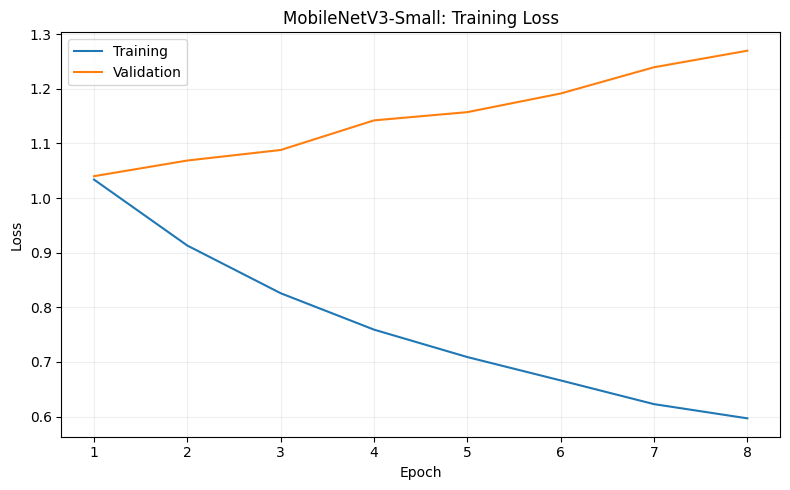

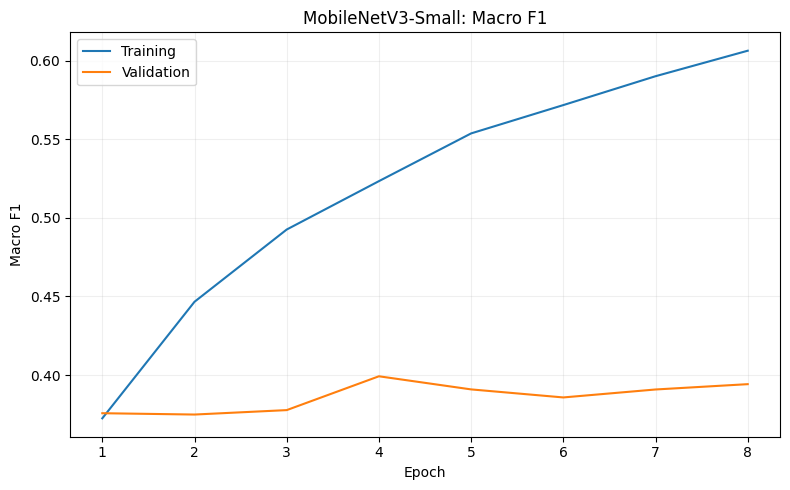

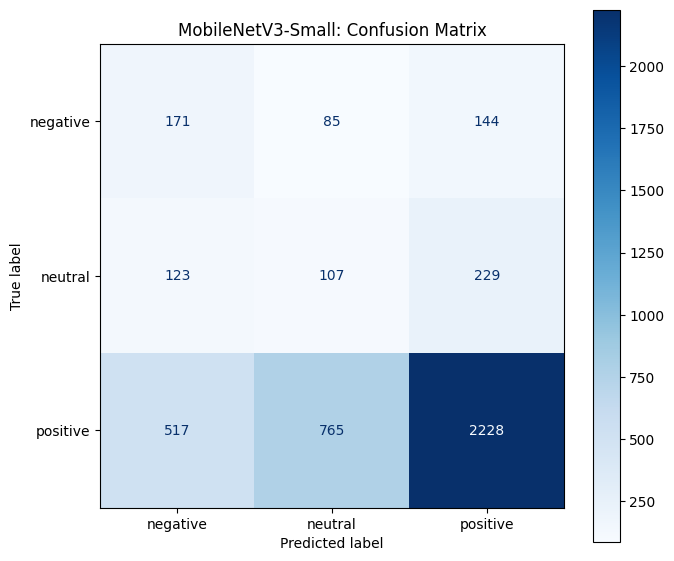

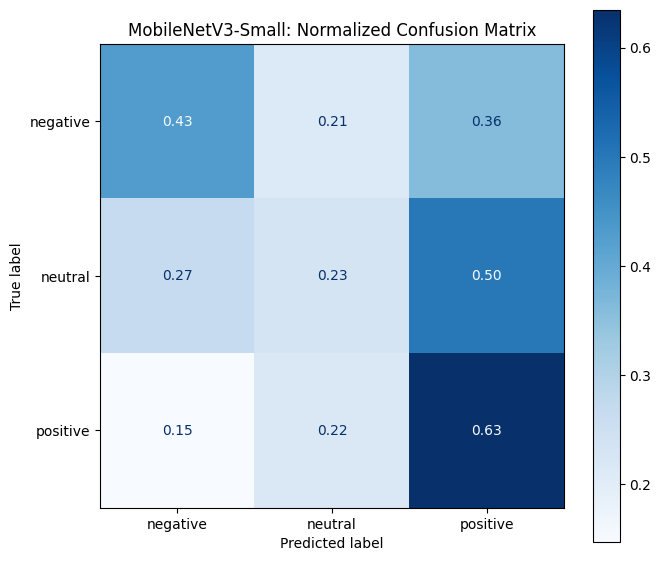

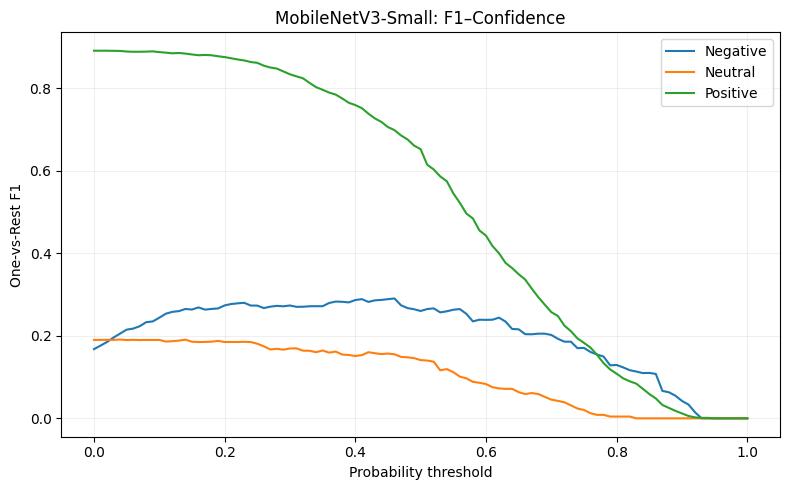

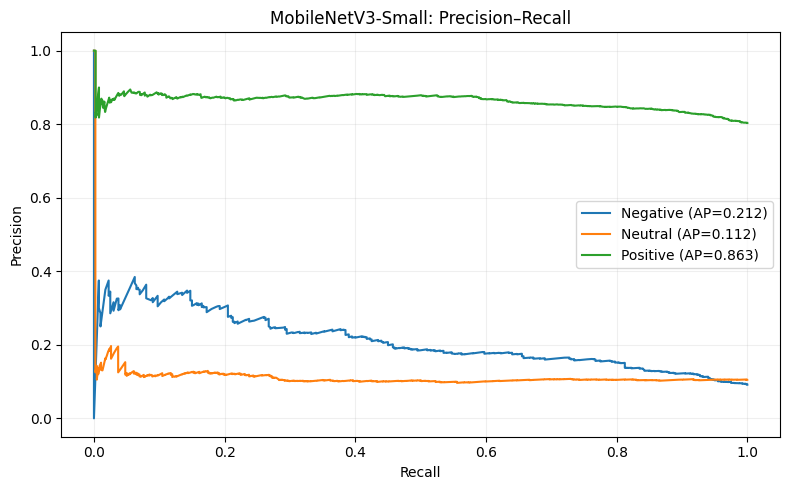

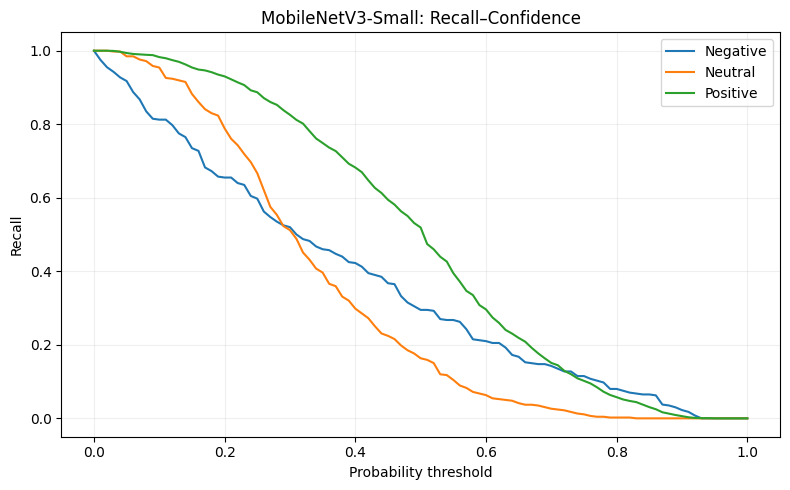

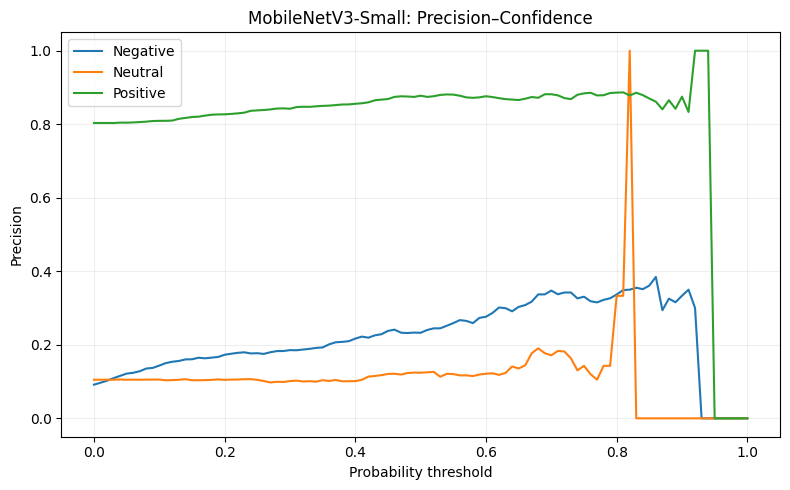


All figures saved to: /kaggle/working/mobilenetv3_results/figures


In [57]:

def save_plot_img(filename):
    plt.tight_layout()
    plt.savefig(
        FIG_IMG / filename,
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()
    plt.close()

# Training loss
plt.figure(figsize=(8, 5))
plt.plot(
    history_df_img["epoch"],
    history_df_img["train_loss"],
    label="Training"
)
plt.plot(
    history_df_img["epoch"],
    history_df_img["val_loss"],
    label="Validation"
)
plt.title("MobileNetV3-Small: Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.2)
save_plot_img("01_training_loss.png")

# Training F1
plt.figure(figsize=(8, 5))
plt.plot(
    history_df_img["epoch"],
    history_df_img["train_macro_f1"],
    label="Training"
)
plt.plot(
    history_df_img["epoch"],
    history_df_img["val_macro_f1"],
    label="Validation"
)
plt.title("MobileNetV3-Small: Macro F1")
plt.xlabel("Epoch")
plt.ylabel("Macro F1")
plt.legend()
plt.grid(alpha=0.2)
save_plot_img("02_training_f1.png")

# Confusion matrix
cm_img = confusion_matrix(
    y_true_img, y_pred_img, labels=[0, 1, 2]
)

fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay(
    cm_img,
    display_labels=classes_img
).plot(
    ax=ax,
    cmap="Blues",
    values_format="d"
)

ax.set_title("MobileNetV3-Small: Confusion Matrix")
save_plot_img("03_confusion_matrix.png")

# Normalized confusion matrix
cm_norm_img = confusion_matrix(
    y_true_img,
    y_pred_img,
    labels=[0, 1, 2],
    normalize="true"
)

fig, ax = plt.subplots(figsize=(7, 6))

ConfusionMatrixDisplay(
    cm_norm_img,
    display_labels=classes_img
).plot(
    ax=ax,
    cmap="Blues",
    values_format=".2f"
)

ax.set_title("MobileNetV3-Small: Normalized Confusion Matrix")
save_plot_img("04_confusion_matrix_normalized.png")

thresholds_img = np.linspace(0, 1, 101)

precision_curves_img = {}
recall_curves_img = {}
f1_curves_img = {}

for i, c in enumerate(classes_img):

    binary_true = (y_true_img == i).astype(int)

    precision_curves_img[c] = []
    recall_curves_img[c] = []
    f1_curves_img[c] = []

    for threshold in thresholds_img:

        binary_pred = (
            probs_img[:, i] >= threshold
        ).astype(int)

        precision_curves_img[c].append(
            precision_score(
                binary_true,
                binary_pred,
                zero_division=0
            )
        )

        recall_curves_img[c].append(
            recall_score(
                binary_true,
                binary_pred,
                zero_division=0
            )
        )

        f1_curves_img[c].append(
            f1_score(
                binary_true,
                binary_pred,
                zero_division=0
            )
        )

# F1-confidence
plt.figure(figsize=(8, 5))

for c in classes_img:
    plt.plot(
        thresholds_img,
        f1_curves_img[c],
        label=c.title()
    )

plt.xlabel("Probability threshold")
plt.ylabel("One-vs-Rest F1")
plt.title("MobileNetV3-Small: F1–Confidence")
plt.legend()
plt.grid(alpha=0.2)
save_plot_img("05_f1_confidence.png")

# Precision-recall
plt.figure(figsize=(8, 5))

for i, c in enumerate(classes_img):

    binary_true = (y_true_img == i).astype(int)

    p, r, _ = precision_recall_curve(
        binary_true,
        probs_img[:, i]
    )

    ap = average_precision_score(
        binary_true,
        probs_img[:, i]
    )

    plt.plot(
        r, p,
        label=f"{c.title()} (AP={ap:.3f})"
    )

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("MobileNetV3-Small: Precision–Recall")
plt.legend()
plt.grid(alpha=0.2)
save_plot_img("06_precision_recall.png")

# Recall-confidence
plt.figure(figsize=(8, 5))

for c in classes_img:
    plt.plot(
        thresholds_img,
        recall_curves_img[c],
        label=c.title()
    )

plt.xlabel("Probability threshold")
plt.ylabel("Recall")
plt.title("MobileNetV3-Small: Recall–Confidence")
plt.legend()
plt.grid(alpha=0.2)
save_plot_img("07_recall_confidence.png")

# Precision-confidence
plt.figure(figsize=(8, 5))

for c in classes_img:
    plt.plot(
        thresholds_img,
        precision_curves_img[c],
        label=c.title()
    )

plt.xlabel("Probability threshold")
plt.ylabel("Precision")
plt.title("MobileNetV3-Small: Precision–Confidence")
plt.legend()
plt.grid(alpha=0.2)
save_plot_img("08_precision_confidence.png")

print("\nAll figures saved to:", FIG_IMG)


In [64]:

summary_img = {
    "model": "MobileNetV3-Small",
    "modality": "image-only",
    "seed": SEED,
    "train_samples": len(train_img),
    "validation_samples": len(val_img),
    "test_samples": len(test_img),
    "best_epoch": best_epoch_img,
    "best_validation_macro_f1": best_f1_img,
    "test_accuracy": test_metrics_img["accuracy"],
    "test_macro_f1": test_metrics_img["macro_f1"],
    "learning_rate": LR,
    "batch_size": BATCH_SIZE,
    "max_epochs": EPOCHS
}

with open(
    OUT_IMG / "experiment_summary.json", "w"
) as f:
    json.dump(summary_img, f, indent=2)

print("Model 2 completed successfully!")
print("Results saved at:", OUT_IMG)


Model 2 completed successfully!
Results saved at: /kaggle/working/mobilenetv3_results


In [65]:

import pandas as pd

print("===== IMAGE LABEL CONSISTENCY CHECK =====")

for name, df in [
    ("Train", train_img),
    ("Validation", val_img),
    ("Test", test_img)
]:
    grouped = df.groupby("resolved_image_path")["sentiment"]

    unique_images = df["resolved_image_path"].nunique()
    conflicting_images = (grouped.nunique() > 1).sum()

    print(f"\n{name}")
    print("Aspect-level rows:", len(df))
    print("Unique images:", unique_images)
    print("Images with conflicting sentiment labels:", conflicting_images)
    print(
        "Percentage of images with conflicting labels:",
        round(100 * conflicting_images / unique_images, 2)
        if unique_images else 0
    )

print("\n===== CROSS-SPLIT IMAGE OVERLAP =====")

train_ids = set(train_img["sample_id"].astype(str))
val_ids = set(val_img["sample_id"].astype(str))
test_ids = set(test_img["sample_id"].astype(str))

print("Train-Val overlap:", len(train_ids & val_ids))
print("Train-Test overlap:", len(train_ids & test_ids))
print("Val-Test overlap:", len(val_ids & test_ids))


===== IMAGE LABEL CONSISTENCY CHECK =====

Train
Aspect-level rows: 29885
Unique images: 9537
Images with conflicting sentiment labels: 2652
Percentage of images with conflicting labels: 27.81

Validation
Aspect-level rows: 8603
Unique images: 2716
Images with conflicting sentiment labels: 811
Percentage of images with conflicting labels: 29.86

Test
Aspect-level rows: 4369
Unique images: 1373
Images with conflicting sentiment labels: 386
Percentage of images with conflicting labels: 28.11

===== CROSS-SPLIT IMAGE OVERLAP =====
Train-Val overlap: 0
Train-Test overlap: 0
Val-Test overlap: 0


In [66]:

import pandas as pd

print("===== IMAGE-ONLY EMPIRICAL ACCURACY CEILING =====")

image_label_counts = (
    test_img.groupby(
        ["resolved_image_path", "sentiment"]
    )
    .size()
    .unstack(fill_value=0)
)

max_correct = image_label_counts.max(axis=1).sum()

accuracy_ceiling = max_correct / len(test_img)

print("Total test rows:", len(test_img))
print("Unique images:", len(image_label_counts))
print("Maximum consistent-image correct predictions:", max_correct)
print(f"Empirical accuracy ceiling: {accuracy_ceiling:.4%}")

print(
    "Unavoidable errors under this image-only setup:",
    len(test_img) - max_correct
)


===== IMAGE-ONLY EMPIRICAL ACCURACY CEILING =====
Total test rows: 4369
Unique images: 1373
Maximum consistent-image correct predictions: 3830
Empirical accuracy ceiling: 87.6631%
Unavoidable errors under this image-only setup: 539


In [68]:

print("===== OUR DATASET DETAILS =====")

for name, df in [
    ("Train", train_img),
    ("Validation", val_img),
    ("Test", test_img)
]:
    print(f"\n{name.upper()}")
    print("Total aspect records:", len(df))
    print("Unique post IDs:", df["sample_id"].nunique())
    print("Sentiment distribution:")
    print(df["sentiment"].value_counts())

print("\nTest columns:")
print(test_img.columns.tolist())


===== OUR DATASET DETAILS =====

TRAIN
Total aspect records: 29885
Unique post IDs: 9537
Sentiment distribution:
sentiment
positive    24065
neutral      3289
negative     2531
Name: count, dtype: int64

VALIDATION
Total aspect records: 8603
Unique post IDs: 2716
Sentiment distribution:
sentiment
positive    6777
neutral     1002
negative     824
Name: count, dtype: int64

TEST
Total aspect records: 4369
Unique post IDs: 1373
Sentiment distribution:
sentiment
positive    3510
neutral      459
negative     400
Name: count, dtype: int64

Test columns:
['sample_id', 'text', 'image_path', 'aspect', 'sentiment', 'resolved_image_path']
